Imports.

In [21]:
from numpy import arange, array, average, cov, corrcoef, degrees, diff, ix_, meshgrid, sqrt, std
from numpy.linalg import eig, norm
from scipy.optimize import minimize
from sklearn.metrics.pairwise import laplacian_kernel
from math import atan
from pandas import DataFrame, read_csv, Series
from seaborn import scatterplot
from matplotlib.patches import Ellipse
from matplotlib.pyplot import show, axes, gca

In [22]:
# find the ROOT & DATA folder.

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

Load Data

In [23]:
# times to maturity - changeable
# tau is the maturities 2,2.25,2.5....,10 (33 in total).  Index 0 is 2y and each step adds a quarter
tau = arange(2, 10.25, 0.25)
# read the csv - fixed income
# .loc[:, tau.astype('str')] -> picks the columns whose headers are 2.0,2.25,...
# drops any day missing yields
db_yields_data = read_csv(DATA_DIR/"fixed_income_db_yields/data.csv", index_col=0).loc[:, tau.astype('str')].dropna(axis=0)
# .T Transposes so y is maturities x days (33 rows, 1 column per day)
y = array(db_yields_data).T

print(y)

[[0.05039825 0.04986652 0.05025614 ... 0.00361957 0.00367799 0.00365734]
 [0.05013448 0.04952644 0.04991016 ... 0.0037612  0.00379841 0.00377868]
 [0.04993379 0.04931793 0.04969322 ... 0.00391591 0.00395186 0.00393004]
 ...
 [0.05063565 0.050053   0.05039021 ... 0.01665054 0.01662194 0.01665153]
 [0.05069891 0.05015524 0.05043091 ... 0.01706951 0.01703826 0.01706212]
 [0.05075792 0.05016578 0.05043963 ... 0.01746463 0.01744022 0.01747666]]


Step 1.

Changes in the Yield

In [24]:
# changes in the yield to maturity
x = diff(y, n=1, axis=1)

print(x)

[[-5.31727956e-04  3.89620529e-04  2.64894223e-04 ...  1.30942788e-05
   5.84248068e-05 -2.06509273e-05]
 [-6.08045901e-04  3.83722821e-04  4.78626478e-04 ...  1.25500278e-05
   3.72039506e-05 -1.97229641e-05]
 [-6.15856383e-04  3.75287845e-04  2.26066901e-04 ...  9.29040024e-06
   3.59518427e-05 -2.18138631e-05]
 ...
 [-5.82649076e-04  3.37207147e-04  1.24945686e-04 ... -4.20546748e-05
  -2.86023771e-05  2.95888046e-05]
 [-5.43669330e-04  2.75666899e-04  1.48020032e-04 ... -3.92556480e-05
  -3.12483850e-05  2.38593415e-05]
 [-5.92145514e-04  2.73855881e-04  1.84647159e-04 ... -3.66841357e-05
  -2.44089319e-05  3.64369870e-05]]


Step 2.

Sample statistics and ellipse plots

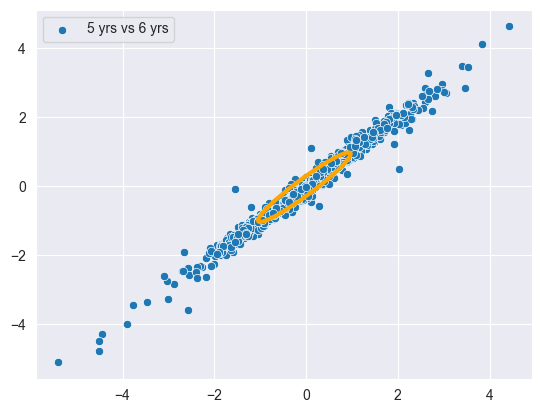

In [14]:
# sample parameters
# mean
# axis=1 averages across the days giving 1 umber per maturity
m_hat_hfp_x = average(x, axis=1)
# covariance
# bias=True divides T rather than T-1 (hfp -> historical with flat probabilities)
# estimators gives each day equal weight 1/T
s2_hat_hfp_x = cov(x, bias=True)
# standard deviation
s_hat_hfp_x = std(x, axis=1)
# correlation
# is the 33x33 correlation matrix: the real-data counterpart for the homework's Toeplitz matrix
c2_hat_hfp_x = corrcoef(x)

# parameters for ellipses based on covariance and radius (width, height, angle)
# This is the helper that turns a 2x2 matrix into an ellipse to draw.
ellipse_params = lambda sigma2, r: (2*sqrt(eig(sigma2)[0][0]), 2*r*sqrt(eig(sigma2)[0][1]), degrees(atan(eig(sigma2)[1][1,0]/eig(sigma2)[1][1,1])))

# standardized 5 vs 6 years changes in yield to maturity
# takes the 5y and 6y rows and divides each by its std, putting both on the same scale
x_5vs6 = x[[12, 16], :]/s_hat_hfp_x[[12, 16]].reshape(-1, 1)  # scenarios
m = m_hat_hfp_x[[12, 16]]/s_hat_hfp_x[[12, 16]]  # mean
# ix_([12, 16], [12, 16]) -> cuts the 2x2 block for those 2 maturities out of the big correlation matrix
c2 = c2_hat_hfp_x[ix_([12, 16], [12, 16])]  # correlations
# ellipse of 5 vs 6 years changes in yield to maturity
width, height, angle = ellipse_params(c2, 2)
ellipse_5vs6 = Ellipse(m, width, height, angle=angle, fill=False, color='orange', lw=3)
# 5 vs 6 years changes in yield to maturity
scatterplot(x=x_5vs6[0, :], y=x_5vs6[1, :], label='5 yrs vs 6 yrs')
gca().add_patch(ellipse_5vs6)
show();

# The plot shows each day as a dot, with a  2-sd ellipse on top.

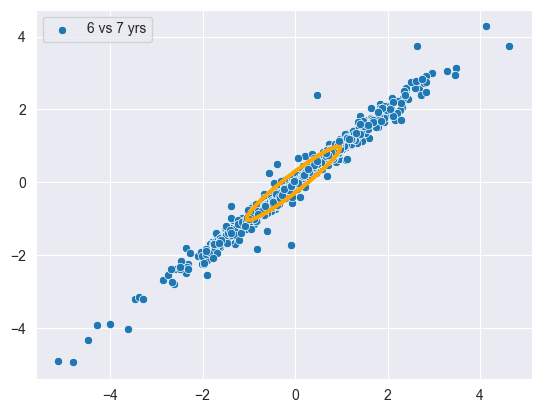

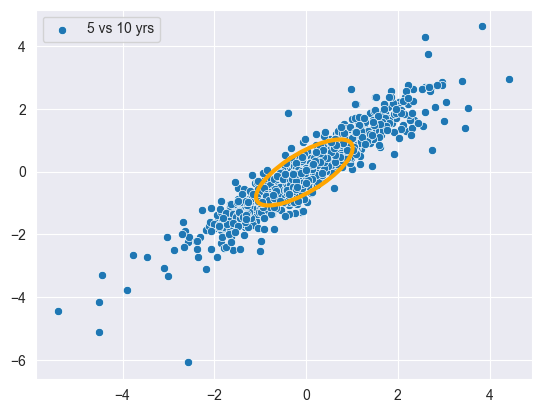

In [15]:
# standardized 6 vs 7 years changes in yield to maturity
x_6vs7 = x[[16, 20], :]/s_hat_hfp_x[[16, 20]].reshape(-1, 1)  # scenarios
m = m_hat_hfp_x[[16, 20]]/s_hat_hfp_x[[16, 20]]  # mean
c2 = c2_hat_hfp_x[ix_([16, 20], [16, 20])]  # correlations
# ellipse of 6 vs 7 years changes in yield to maturity
width, height, angle = ellipse_params(c2, 2)
ellipse_6vs7 = Ellipse(m, width, height, angle=angle, fill=False, color='orange', lw=3)
# 6 vs 7 years changes in yield to maturity
scatterplot(x=x_6vs7[0,:], y=x_6vs7[1, :], label='6 vs 7 yrs')
gca().add_patch(ellipse_6vs7); show()

# standardized 5 vs 10 years changes in yield to maturity
x_5vs10 = x[[12, 32], :]/s_hat_hfp_x[[12, 32]].reshape(-1, 1)  # scenarios
m = m_hat_hfp_x[[12, 32]]/s_hat_hfp_x[[12, 32]]  # mean
c2 = c2_hat_hfp_x[ix_([12, 32], [12, 32])]  # correlations
# ellipse of 5 vs 10 years changes in yield to maturity
width, height, angle = ellipse_params(c2, 2)
ellipse_5vs10 = Ellipse(m, width, height, angle=angle, fill=False, color='orange', lw=3)
# 5 vs 10 years changes in yield to maturity
scatterplot(x=x_5vs10[0, :], y=x_5vs10[1, :], label='5 vs 10 yrs')
gca().add_patch(ellipse_5vs10);

Step3.

Fit the decaying-correlation curve

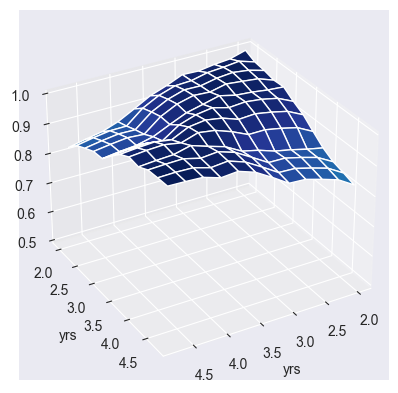

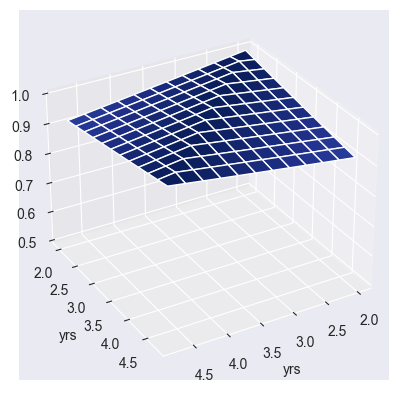

In [18]:
# The model is correlation with a single parameter.  A large y means correlation dies off fast
# A small Y means the curve moves as 1 block.

# square Frobenius norm between two correlations
# fr_norm measures how far the model matrix is from the real one.
fr_norm = lambda g: norm(laplacian_kernel(tau.reshape(-1, 1), tau.reshape(-1, 1), g) - c2_hat_hfp_x, ord='f')

# minimize searches for y >= 0 that makes that distance smallest, starting from 1.
gamma_star = minimize(fr_norm, 1., bounds=[(0, None)])['x'][0]  # calibrate parameter gamma
# This is the fitted Toeplitz correlation matrix
c2_star = laplacian_kernel(tau.reshape(-1, 1), tau.reshape(-1, 1), gamma_star)  # Toeplitz correlation

# empirical correlation
ax = axes(projection='3d'); ax.view_init(azim=60)
xs, ys = meshgrid(tau[:12], tau[:12])
im1 = ax.plot_surface(xs, ys, c2_hat_hfp_x[:12, :12], cmap='YlGnBu', vmin=0.5, vmax=1)
ax.set(xlabel='yrs', ylabel='yrs', zlim=[0.5, 1]); show()

# fitted correlation
ax = axes(projection='3d'); ax.view_init(azim=60)
im2 = ax.plot_surface(xs, ys, c2_star[:12, :12], cmap='YlGnBu', vmin=0.5, vmax=1)
ax.set(xlabel='yrs', ylabel='yrs', zlim=[0.5, 1]);

# displaying 3D surfaces of the correlation matrix for the 1st 12 maturities (2y to 4.75y)
# real data first, then the fit.
# Both should look like a ridge along the diagonal at 1, sloping down as you move away from it.
# If the 2 surfaces look alike , one y captures the structure well

Save for the next notebook

In [20]:
output = DataFrame({'y': Series(y.reshape(-1)), 'n_bar': Series(y.shape[0]), 't_bar': Series(y.shape[1]),
                   'tau': Series(tau.squeeze()), 'm_hat_hfp_x': Series(m_hat_hfp_x), 's_hat_hfp_x': Series(s_hat_hfp_x),
                   's2_hat_hfp_x': Series(s2_hat_hfp_x.reshape(-1)), 'gamma_star': Series(gamma_star)})

output.to_csv(DATA_DIR/'temporary-databases/db_pca_yield_data.csv')

Making the story visible.

6 extra plots to show the point, using variables already populated from this notebook.

V1-V2 Show how what X is.

V3-V5 show that its correlation has a "depends on distance" structure.

V4 and V6 show that structure summarised by one number 'y'

The next notebook 's_pca_yield' and asks which few shapes explain most of the movement.

The decay that we see in V4 is why this answer turns out to be just 3.



In [33]:
import matplotlib.pyplot as plt
from numpy import linspace, exp, abs

1: What the raw data is?

This plots 5 whole yield curves at different dates from the sample.

Each line is 1 row of y turned on its sides (1 day all 33 maturities)

This is the object PCA will later break into level, slope, and curvature

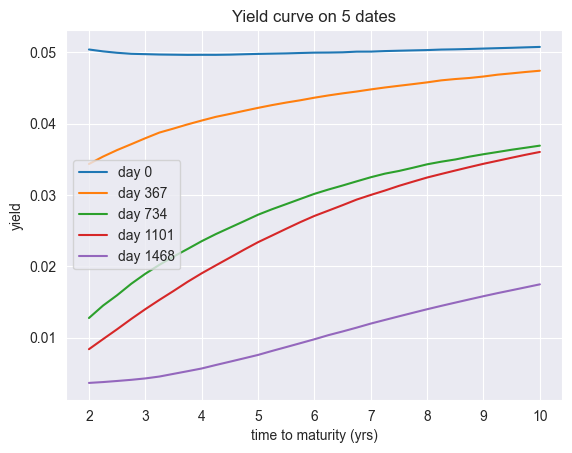

In [34]:
t_bar = y.shape[1]
for t in linspace(0, t_bar - 1, 5).astype(int):
    plt.plot(tau, y[:, t], label=f'day {t}')
plt.xlabel('time to maturity (yrs)'); plt.ylabel('yield'); plt.title('Yield curve on 5 dates')
plt.legend()
plt.show();

V2:

Why we use changes, not levels (step 1)

The top panel shows yield levels wandering around over the years.

The bottom panel shows the daily changes bouncing around zero with a roughly constant spread

Thats the visual meaning of 'x = diff(y)'

changes look the same in any period, so averaging over time makes sense.

3 lines moving together, this is the correlation the rest of the notebook measures

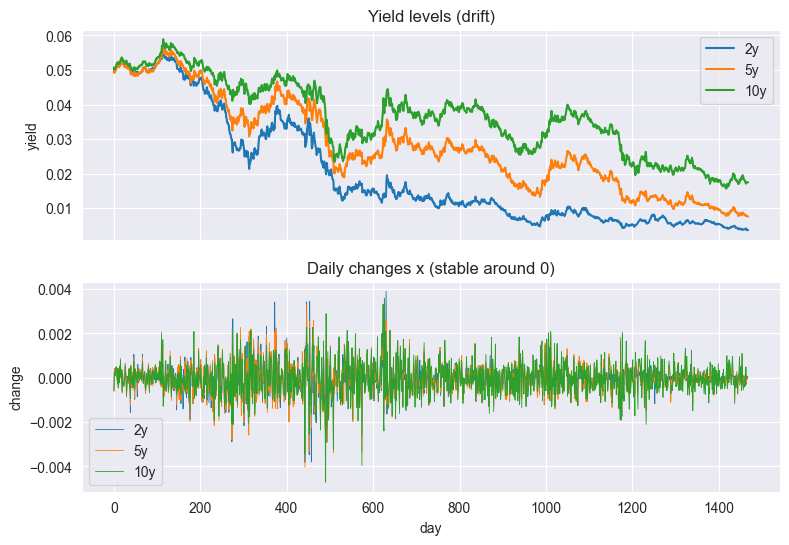

In [35]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for i, lab in [(0, '2y'), (12, '5y'), (32, '10y')]:
    ax1.plot(y[i, :], label=lab)
    ax2.plot(x[i, :], label=lab, lw=0.6)
ax1.set(title='Yield levels (drift)', ylabel='yield'); ax1.legend()
ax2.set(title='Daily changes x (stable around 0)', xlabel='day', ylabel='change'); ax2.legend()
plt.show()

V4:

The Key Plot (step 3 in 1 picture)

Every dot is 1 pair of maturities

The x-axis is how far apart they are, the y-axis is their correlation.

If correlation depends on where you are on the curve, the dots would be scattered all over.

Instead the form a tight band that falls with distance.

The red line is the fitted model exp(-y*.d).

This 1 plot explains what laplacian_kernel and minimize are doing,

Drawing the best single decay curve through these dots

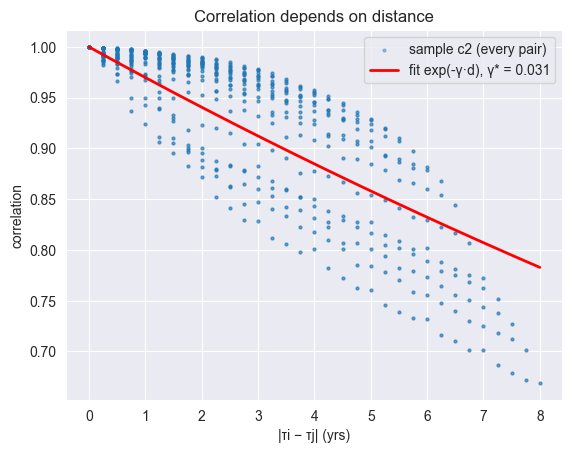

In [28]:
d = abs(tau.reshape(-1, 1) - tau.reshape(1, -1))
plt.scatter(d.flatten(), c2_hat_hfp_x.flatten(), s=4, alpha=0.4, label='sample c2 (every pair)')
d_grid = linspace(0, d.max(), 200)
plt.plot(d_grid, exp(-gamma_star * d_grid), color='red', lw=2,
         label=f'fit exp(-γ·d), γ* = {gamma_star:.3f}')
plt.xlabel('|τi − τj| (yrs)'); plt.ylabel('correlation'); plt.title('Correlation depends on distance')
plt.legend()
plt.show();

V5:

Toeplitz, row by row

This plots 4 rows of the matrix, how the 2y, 5y, 8y and 10y yields each correlate with every other maturity.

Each curve is a peak at its own maturity, with roughly the same shape slid along the x-axis.

Same shape, shifted is what Toeplitz means.

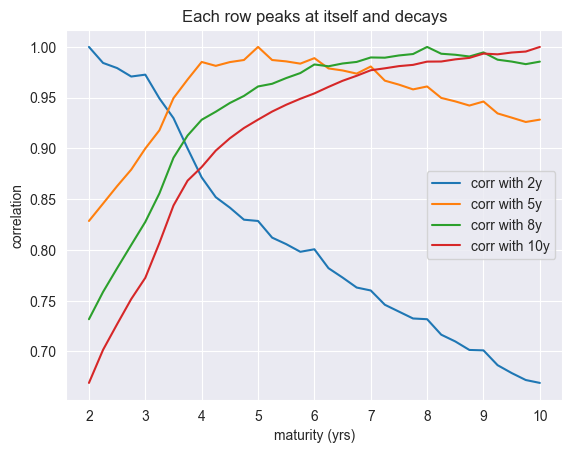

In [36]:
for i, lab in [(0, '2y'), (12, '5y'), (24, '8y'), (32, '10y')]:
    plt.plot(tau, c2_hat_hfp_x[i, :], label=f'corr with {lab}')
plt.xlabel('maturity (yrs)'); plt.ylabel('correlation'); plt.title('Each row peaks at itself and decays')
plt.legend()
plt.show();

V6:

How good is the fit, and how y was found

The left panel shows where the 1 parameter model misses.

White means a good fit, red or blue patches show where real correlations are higher or lower than the model says.

Any systematic pattern, such as misses concentrated at the short end, is what one y cat capture.

The right panel shows the objective fr_norm evaluated across many values of y.

Its a U-shaped curve and the red line sits at the bottom.

Thats literally what minimize searched for.


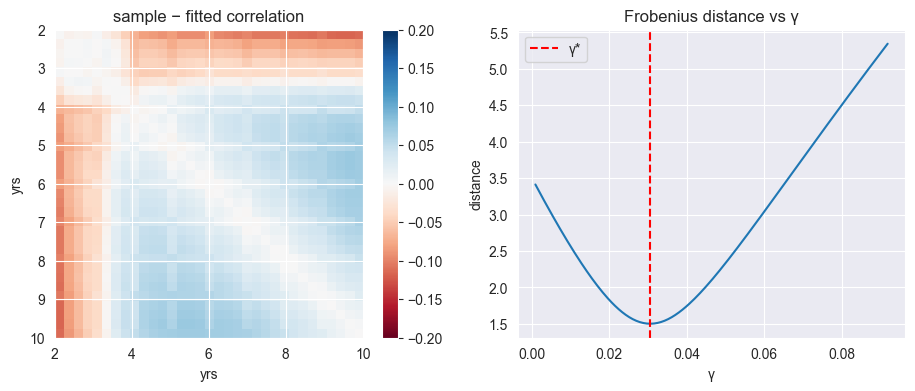

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
im = ax1.imshow(c2_hat_hfp_x - c2_star, cmap='RdBu', vmin=-0.2, vmax=0.2,
                extent=[tau[0], tau[-1], tau[-1], tau[0]])
fig.colorbar(im, ax=ax1); ax1.set(title='sample − fitted correlation', xlabel='yrs', ylabel='yrs')
g_grid = linspace(0.001, 3 * gamma_star, 200)
ax2.plot(g_grid, [fr_norm(g) for g in g_grid])
ax2.axvline(gamma_star, color='red', ls='--', label='γ*')
ax2.set(title='Frobenius distance vs γ', xlabel='γ', ylabel='distance');
ax2.legend()
plt.show()